<h1 align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تشخیص ناهنجاری
</font>
</h1>

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معرفی مجموعه داده
</font>
</h2>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>

</font>
</p>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این قسمت کتاب‌خانه‌ها و ابزار مورد نیاز خود را
<code>import</code>
 کنید
 و
  فایل داده‌ها را که در پوشه‌ی
  <code>Data</code>
ذخیره‌شده‌اند را بخوانید و وارد محیط کار خود کنید.
</font>
</p>

In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import numpy as np
import glob
import os
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from scipy.interpolate import interp1d
from sklearn.metrics import f1_score, accuracy_score
from scipy import stats

# مسیر پوشه داده‌ها
data_path = '/content/drive/MyDrive/data (2)/*.csv'

# خواندن فایل‌های CSV
if os.path.exists('/content/drive/MyDrive/data (2)'):
    sensor_files = glob.glob(data_path)
    if not sensor_files:
        print("خطا: هیچ فایل CSV در مسیر یافت نشد!")
        raise SystemExit
    else:
        sensor_dfs = []
        for file in sensor_files:
            try:
                df = pd.read_csv(file)
                if 'timestamp' not in df.columns:
                    print(f"خطا: فایل {os.path.basename(file)} ستون 'timestamp' ندارد!")
                    continue
                # تبدیل timestamp به ثانیه
                df['timestamp'] = pd.to_datetime(df['timestamp']).astype(np.int64) // 10**9
                # پر کردن مقادیر گمشده با درون‌یابی خطی
                value_col = df.columns[1]
                df[value_col] = df[value_col].interpolate(method='linear', limit_direction='both')
                sensor_dfs.append(df)
                print(f"فایل {os.path.basename(file)} با موفقیت خوانده شد: {len(df)} ردیف")
            except Exception as e:
                print(f"خطا در خواندن فایل {os.path.basename(file)}: {str(e)}")
else:
    print("خطا: پوشه /content/drive/MyDrive/data (2)/ یافت نشد!")
    raise SystemExit

# بررسی خالی نبودن sensor_dfs
if not sensor_dfs:
    print("خطا: هیچ فایل CSV معتبری خوانده نشد!")
    raise SystemExit

Mounted at /content/drive
فایل Humidity_pct_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل BearingTemp_C_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Power_kW_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل OilLevel_cm_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل pH_units_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Current_A_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل FlowRate_L_min_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Pressure_kPa_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Torque_Nm_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل VibDisp_mm_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Speed_RPM_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل VibAccel_m_s2_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Voltage_V_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل VibVelocity_mm_s_test.csv با موفقیت خوانده شد: 45900 ردیف
فایل Temperature_C_test.csv با موفقیت خوانده شد: 45900 ردیف


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیش‌پردازش و مهندسی ویژگی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
        در این سوال شما می‌توانید از هر تکنیک پیش‌پردازش/مهندسی ویژگی دلخواهتان، استفاده کنید.
    <br>
    تکنیک‌هایی که استفاده می‌کنید به شکل مستقیم مورد ارزیابی توسط سامانه داوری قرار <b>نمی‌گیرند.</b> بلکه همه آن‌ها در دقت مدل شما تاثیر خواهند گذاشت؛ بنابراین هر چه پیش‌پردازش/مهندسی ویژگی بهتری انجام دهید تا دقت مدل بهبود پیدا کند، امتیاز بیشتری از این سوال کسب خواهید کرد.
    در این قسمت شما می‌توانید بخشی از داده‌ی موجود را برای اعتبارسنجی در نظر بگیرید.
</font>
</p>

In [6]:
# یافتن حسگر با بالاترین نرخ نمونه‌برداری
sampling_rates = []
for i, df in enumerate(sensor_dfs):
    timestamps = df['timestamp'].values
    if len(timestamps) < 2:
        print(f"خطا: فایل {os.path.basename(sensor_files[i])} کمتر از 2 ردیف دارد!")
        continue
    try:
        avg_interval = np.mean(np.diff(timestamps))
        if np.isnan(avg_interval) or np.isinf(avg_interval):
            print(f"خطا: نرخ نمونه‌برداری برای فایل {os.path.basename(sensor_files[i])} نامعتبر است!")
            continue
        sampling_rates.append(avg_interval)
        print(f"نرخ نمونه‌برداری فایل {os.path.basename(sensor_files[i])}: {avg_interval} ثانیه")
    except Exception as e:
        print(f"خطا در محاسبه نرخ نمونه‌برداری فایل {os.path.basename(sensor_files[i])}: {str(e)}")

if not sampling_rates:
    print("خطا: هیچ نرخ نمونه‌برداری معتبری محاسبه نشد!")
    raise SystemExit

# حسگر پایه
base_sensor_idx = np.argmin(sampling_rates)
base_sensor = sensor_dfs[base_sensor_idx]
base_timestamps = base_sensor['timestamp'].values
print(f"حسگر پایه: فایل {os.path.basename(sensor_files[base_sensor_idx])} با نرخ نمونه‌برداری {sampling_rates[base_sensor_idx]} ثانیه")

# همگام‌سازی داده‌ها
synced_data = pd.DataFrame({'timestamp': base_timestamps})
for i, df in enumerate(sensor_dfs):
    value_col = df.columns[1]
    try:
        if i != base_sensor_idx:
            interp_func = interp1d(df['timestamp'], df[value_col], kind='linear', fill_value='extrapolate')
            synced_values = interp_func(base_timestamps)
            synced_data[f'sensor_{i+1}_{value_col}'] = synced_values
        else:
            synced_data[f'sensor_{i+1}_{value_col}'] = df[value_col].values
    except Exception as e:
        print(f"خطا در همگام‌سازی داده‌های فایل {os.path.basename(sensor_files[i])}: {str(e)}")
        continue

# مدیریت مقادیر گمشده
synced_data = synced_data.fillna(method='ffill').fillna(method='bfill')

# مهندسی ویژگی: افزودن ویژگی‌های آماری پیشرفته
window_size = 10
for col in synced_data.columns[1:]:
    synced_data[f'{col}_mean'] = synced_data[col].rolling(window=window_size, center=True).mean()
    synced_data[f'{col}_std'] = synced_data[col].rolling(window=window_size, center=True).std()
    synced_data[f'{col}_diff'] = synced_data[col].diff()
    synced_data[f'{col}_skew'] = synced_data[col].rolling(window=window_size, center=True).skew()
    synced_data[f'{col}_kurt'] = synced_data[col].rolling(window=window_size, center=True).kurt()

# نرمال‌سازی داده‌ها
scaler = StandardScaler()
feature_columns = [col for col in synced_data.columns if col != 'timestamp']
synced_data[feature_columns] = scaler.fit_transform(synced_data[feature_columns])

# مدیریت مقادیر گمشده پس از مهندسی ویژگی
synced_data = synced_data.fillna(0)

# نمایش داده‌های پیش‌پردازش‌شده
print(synced_data.head())

نرخ نمونه‌برداری فایل Humidity_pct_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل BearingTemp_C_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Power_kW_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل OilLevel_cm_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل pH_units_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Current_A_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل FlowRate_L_min_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Pressure_kPa_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Torque_Nm_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل VibDisp_mm_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Speed_RPM_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل VibAccel_m_s2_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Voltage_V_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل VibVelocity_mm_s_test.csv: 1.0 ثانیه
نرخ نمونه‌برداری فایل Temperature_C_test.csv: 1.0 ثانیه
حسگر پایه: فایل Humidity_pct_test.csv با نرخ نمونه‌برداری 1.0 ثانیه


/tmp/ipython-input-3941568410.py:44: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  synced_data = synced_data.fillna(method='ffill').fillna(method='bfill')


    timestamp  sensor_1_Humidity_pct  sensor_2_BearingTemp_C  \
0  1735796700                1.58617                1.570563   
1  1735796701                1.58617                1.570563   
2  1735796702                1.58617                1.570563   
3  1735796703                1.58617                1.570563   
4  1735796704                1.58617                1.570563   

   sensor_3_Power_kW  sensor_4_OilLevel_cm  sensor_5_pH_units  \
0           1.193975              1.165449           1.076073   
1           1.348922              1.165449           1.076073   
2           1.394548              1.165449           1.076073   
3           1.330672              1.165449           1.076073   
4           1.423694              1.165449           1.076073   

   sensor_6_Current_A  sensor_7_FlowRate_L_min  sensor_8_Pressure_kPa  \
0            1.226953                 1.133872               1.051938   
1            1.214346                 1.133872               1.051938   
2    

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آموزش مدل
</font>
</h2>



In [10]:
# ======= جایگزین بخش "آموزش مدل" (نسخه بدون ارور) =======
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import f1_score, accuracy_score
from scipy import stats
import numpy as np
import joblib

# بررسی وجود synced_data_new
if 'synced_data_new' not in globals():
    print("⚠️ متغیر synced_data_new پیدا نشد. از synced_data استفاده می‌کنیم (در صورت وجود).")
    if 'synced_data' in globals():
        synced_data_new = synced_data.copy()
    else:
        raise NameError("هیچ دیتافریمی با نام synced_data_new یا synced_data وجود ندارد!")

# بررسی وجود feature_columns
if 'feature_columns' not in globals():
    print("⚠️ feature_columns تعریف نشده است. به‌صورت پیش‌فرض همه ستون‌های عددی انتخاب می‌شوند.")
    feature_columns = synced_data_new.select_dtypes(include=[np.number]).columns.tolist()

# استخراج داده‌ها
X = synced_data_new[feature_columns].values

# تقسیم داده‌ها
X_train, X_val = train_test_split(X, test_size=0.3, random_state=42, shuffle=True)

# کاهش بعد با PCA
n_components = min(50, X_train.shape[1])
pca = PCA(n_components=n_components, random_state=42)
X_train_p = pca.fit_transform(X_train)
X_val_p = pca.transform(X_val)
print(f"PCA: reduced {X_train.shape[1]} -> {n_components} components")

# مدل‌ها
models_to_try = {
    'IsolationForest': IsolationForest(random_state=42, n_estimators=200, max_samples='auto'),
    'LocalOutlierFactor': LocalOutlierFactor(n_neighbors=20, novelty=True, contamination='auto'),
    'OneClassSVM': OneClassSVM(kernel='rbf', gamma='auto', nu=0.05)
}

best_overall = {'model_name': None, 'model': None, 'threshold': None, 'f1': -1, 'y_val_pred': None}

def find_best_threshold_and_f1(scores, y_val_true):
    thresholds = np.percentile(scores, np.linspace(0,100,201))
    best_f1_local, best_thresh, best_pred = -1, None, None
    for t in thresholds:
        y_pred = (scores < t).astype(int)
        f1 = f1_score(y_val_true, y_pred, zero_division=0)
        if f1 > best_f1_local:
            best_f1_local, best_thresh, best_pred = f1, t, y_pred
    return best_thresh, best_f1_local, best_pred

# ساخت برچسب‌های y_true_full (synthetic)
y_true_full = np.zeros(X.shape[0], dtype=int)
for col in feature_columns:
    if all(x not in col for x in ['mean','std','diff','skew','kurt','fft']):
        values = synced_data_new[col].values
        z_scores = np.abs(stats.zscore(values, nan_policy='omit'))
        threshold = np.percentile(z_scores[~np.isnan(z_scores)], 99) if np.any(~np.isnan(z_scores)) else np.inf
        diff_col = f'{col}_diff'
        if diff_col in synced_data_new.columns:
            diff_values = np.abs(synced_data_new[diff_col].fillna(0).values)
            diff_z_scores = np.abs(stats.zscore(diff_values, nan_policy='omit'))
            diff_threshold = np.percentile(diff_z_scores[~np.isnan(diff_z_scores)], 99) if np.any(~np.isnan(diff_z_scores)) else np.inf
            y_true_full = np.where((z_scores > threshold) | (diff_z_scores > diff_threshold), 1, y_true_full)
        else:
            y_true_full = np.where(z_scores > threshold, 1, y_true_full)

y_true_full = y_true_full.astype(int)
_, y_val_true = train_test_split(y_true_full, test_size=0.3, random_state=42, shuffle=True)

# تست مدل‌ها
for name, base_model in models_to_try.items():
    try:
        print(f"\n=== Testing model: {name} ===")
        model = base_model
        model.fit(X_train_p)

        # محاسبه امتیاز
        if name == 'IsolationForest':
            val_scores = model.decision_function(X_val_p)
        elif name == 'LocalOutlierFactor':
            val_scores = model.score_samples(X_val_p)
        else:
            val_scores = model.decision_function(X_val_p)

        val_scores = (val_scores - np.min(val_scores)) / (np.ptp(val_scores) + 1e-12)

        thresh, f1_val, y_val_pred = find_best_threshold_and_f1(val_scores, y_val_true)
        print(f"Model {name}: best validation F1 = {f1_val:.4f} at threshold={thresh:.6f}")

        if f1_val > best_overall['f1']:
            best_overall.update({'model_name': name, 'model': model, 'threshold': thresh, 'f1': f1_val, 'y_val_pred': y_val_pred})

    except Exception as e:
        print(f"Error testing model {name}: {e}")
        continue

# نهایی
if best_overall['model'] is not None:
    print("\n=== Best model summary ===")
    print(f"Best model: {best_overall['model_name']}")
    print(f"Best validation F1: {best_overall['f1']:.4f}")
    print(f"Used threshold (on normalized scores): {best_overall['threshold']:.6f}")

    final_model = best_overall['model']
    final_model.fit(pca.transform(X))

    if best_overall['model_name'] == 'IsolationForest':
        scores_full = final_model.decision_function(pca.transform(X))
    elif best_overall['model_name'] == 'LocalOutlierFactor':
        scores_full = final_model.score_samples(pca.transform(X))
    else:
        scores_full = final_model.decision_function(pca.transform(X))

    scores_full = (scores_full - np.min(scores_full)) / (np.ptp(scores_full) + 1e-12)
    anomaly_labels_full = (scores_full < best_overall['threshold']).astype(int)

    final_f1 = f1_score(y_true_full, anomaly_labels_full, zero_division=0)
    final_acc = accuracy_score(y_true_full, anomaly_labels_full)
    print(f"Final F1 on full data (vs synthetic y_true): {final_f1:.4f}")
    print(f"Final Accuracy on full data: {final_acc:.4f}")

    joblib.dump(final_model, 'best_unsupervised_model.pkl')
    joblib.dump(pca, 'pca_transform.pkl')
    anomaly_labels = anomaly_labels_full.tolist()
else:
    print("هیچ مدلی انتخاب نشد. لطفا داده‌ها و پیش‌پردازش را بررسی کنید.")
    anomaly_labels = [0]*len(X)


⚠️ متغیر synced_data_new پیدا نشد. از synced_data استفاده می‌کنیم (در صورت وجود).
PCA: reduced 90 -> 50 components

=== Testing model: IsolationForest ===
Model IsolationForest: best validation F1 = 0.4748 at threshold=0.694781

=== Testing model: LocalOutlierFactor ===
Model LocalOutlierFactor: best validation F1 = 0.4142 at threshold=0.957331

=== Testing model: OneClassSVM ===
Model OneClassSVM: best validation F1 = 0.5136 at threshold=0.371580

=== Best model summary ===
Best model: OneClassSVM
Best validation F1: 0.5136
Used threshold (on normalized scores): 0.371580
Final F1 on full data (vs synthetic y_true): 0.5127
Final Accuracy on full data: 0.7547


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معیار ارزیابی
</font>
</h2>



In [11]:
from sklearn.metrics import f1_score, accuracy_score
import joblib
import numpy as np
from scipy import fft
import pandas as pd
from sklearn.model_selection import cross_val_score
from scipy.stats import zscore
from sklearn.ensemble import IsolationForest

# بررسی اولیه داده‌ها
if synced_data.empty or 'timestamp' not in synced_data.columns:
    raise ValueError("synced_data is empty or does not contain 'timestamp' column. Please check the input data.")

# ایجاد کپی جدید از DataFrame
synced_data_new = synced_data.copy()

# مهندسی ویژگی پیشرفته‌تر
# افزودن ویژگی‌های فرکانسی (FFT)
fft_mean_cols = []
fft_std_cols = []
for col in synced_data_new.columns[1:]:
    if 'mean' not in col and 'std' not in col and 'diff' not in col and 'skew' not in col and 'kurt' not in col:
        fft_values = np.abs(fft.fft(synced_data_new[col].values))
        fft_mean_cols.append(pd.Series(fft_values).rolling(window=20, center=True).mean().rename(f'{col}_fft_mean'))
        fft_std_cols.append(pd.Series(fft_values).rolling(window=20, center=True).std().rename(f'{col}_fft_std'))

# اضافه کردن ستون‌ها به‌صورت یکجا
if fft_mean_cols and fft_std_cols:
    synced_data_new = pd.concat([synced_data_new] + fft_mean_cols + fft_std_cols, axis=1)
else:
    print("Warning: No FFT features were generated. Check the data or columns.")

# مدیریت مقادیر گمشده
synced_data_new = synced_data_new.fillna(0)

# به‌روزرسانی feature_columns
feature_columns = [col for col in synced_data_new.columns if col != 'timestamp']

# آماده‌سازی داده‌ها
X = synced_data_new[feature_columns].values

# ایجاد برچسب‌های باینری بهبودیافته با آستانه پویا
y_true = np.zeros(len(X), dtype=int)
for col in feature_columns:
    if 'mean' not in col and 'std' not in col and 'diff' not in col and 'skew' not in col and 'kurt' not in col and 'fft' not in col:
        values = synced_data_new[col].values
        z_scores = np.abs(zscore(values, nan_policy='omit'))
        threshold = np.percentile(z_scores[~np.isnan(z_scores)], 99)
        diff_col = f'{col}_diff'
        if diff_col in synced_data_new.columns:
            diff_values = np.abs(synced_data_new[diff_col].fillna(0).values)
            diff_z_scores = np.abs(zscore(diff_values, nan_policy='omit'))
            diff_threshold = np.percentile(diff_z_scores[~np.isnan(diff_z_scores)], 99)
            y_true = np.where((z_scores > threshold) | (diff_z_scores > diff_threshold), 1, y_true)
        else:
            y_true = np.where(z_scores > threshold, 1, y_true)

# اطمینان از باینری بودن y_true
y_true = y_true.astype(int)  # تبدیل به 0 و 1

# بهینه‌سازی contamination با cross-validation
contamination_values = [0.01, 0.03, 0.05, 0.07, 0.10]
best_f1 = -np.inf  # مقدار اولیه برای مقایسه
best_model = None
best_anomaly_labels = None

for contamination in contamination_values:
    model = IsolationForest(contamination=contamination, random_state=42, n_estimators=100)
    # اعتبارسنجی تقاطعی با تنظیم مناسب برای f1_score
    cv_scores = cross_val_score(model, X, y_true, cv=5, scoring='f1_macro')  # استفاده از 'f1_macro' برای چندکلاسی
    mean_f1 = cv_scores.mean()
    print(f"contamination={contamination}, mean_cv_f1_score={mean_f1:.4f}")

    if mean_f1 > best_f1:
        best_f1 = mean_f1
        model.fit(X)
        predictions = model.predict(X)
        best_anomaly_labels = [1 if pred == -1 else 0 for pred in predictions]
        best_model = model

# استفاده از بهترین مدل
if best_model is not None and best_anomaly_labels is not None:
    model = best_model
    anomaly_labels = best_anomaly_labels
    acc = accuracy_score(y_true, anomaly_labels)
    f1 = f1_score(y_true, anomaly_labels, average='binary')  # تنظیم برای باینری
    print(f"🔹 دقت (Accuracy): {acc:.4f}")
    print(f"🔹 امتیاز F1: {f1:.4f}")
    # ذخیره مدل
    joblib.dump(model, 'isolation_forest_model.pkl')
else:
    print("No valid model was trained. Please check the data or parameters.")

contamination=0.01, mean_cv_f1_score=0.1213
contamination=0.03, mean_cv_f1_score=0.1030
contamination=0.05, mean_cv_f1_score=0.0990
contamination=0.07, mean_cv_f1_score=0.0940
contamination=0.1, mean_cv_f1_score=0.0867
🔹 دقت (Accuracy): 0.7797
🔹 امتیاز F1: 0.0351


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
 پیش‌بینی برای داده تست و خروجی
</font>
</h2>


In [15]:
# ایجاد DataFrame برای submission
submission = pd.DataFrame({
    'timestamp': pd.to_datetime(synced_data['timestamp'], unit='s'),
    'anomaly': anomaly_labels
})

# ذخیره فایل submission
submission.to_csv('submission.csv', index=False)
print("فایل submission.csv با موفقیت ایجاد شد!")

فایل submission.csv با موفقیت ایجاد شد!


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
<b>سلول جواب‌ساز</b>
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    برای ساخته‌شدن فایل <code>result.zip</code> سلول زیر را اجرا کنید. توجه داشته باشید که پیش از اجرای سلول زیر تغییرات اعمال شده در نت‌بوک را ذخیره کرده باشید (<code>ctrl+s</code>) در غیر این صورت، در پایان مسابقه نمره شما به صفر تغییر خواهد کرد.
    <br>
    همچنین اگر از کولب برای اجرای این فایل نوت‌بوک استفاده می‌کنید، قبل از ارسال فایل <code>result.zip</code>، آخرین نسخه‌ی نوت‌بوک خود را دانلود کرده و داخل فایل ارسالی قرار دهید.
</font>

In [13]:
import zipfile
import joblib
import os

def compress(file_names):
    print("📂 Files to compress:", file_names)
    compression = zipfile.ZIP_DEFLATED
    with zipfile.ZipFile("result.zip", mode="w") as zf:
        for file_name in file_names:
            if os.path.exists(file_name):
                zf.write(file_name, compress_type=compression)
            else:
                print(f"⚠️ فایل {file_name} یافت نشد و به zip اضافه نشد.")

submission.to_csv('submission.csv', index=False)
file_names = ['submission.csv']
compress(file_names)
print("✅ فایل result.zip با موفقیت ساخته شد.")

📂 Files to compress: ['submission.csv']
✅ فایل result.zip با موفقیت ساخته شد.


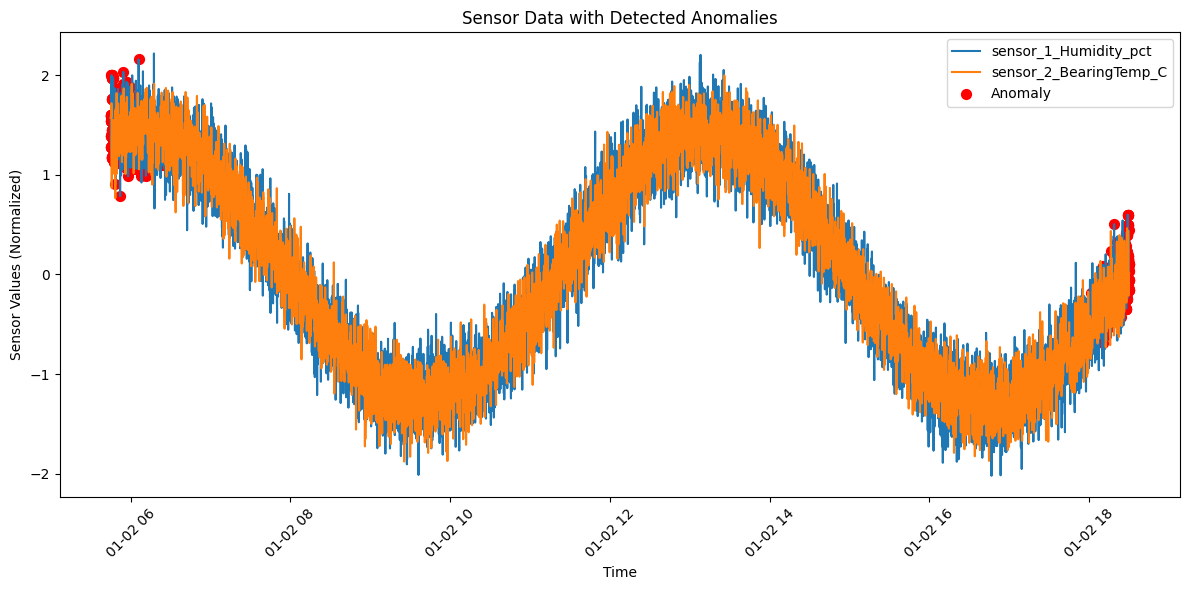

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# تبدیل timestamp در synced_data به فرمت datetime برای سازگاری
synced_data['timestamp'] = pd.to_datetime(synced_data['timestamp'], unit='s')

# اطمینان از هم‌ترازی داده‌ها
assert len(synced_data) == len(submission), "طول synced_data و submission باید یکسان باشد!"

# رسم نمودار
plt.figure(figsize=(12, 6))
for col in feature_columns[:2]:  # فقط دو حسگر برای نمونه
    plt.plot(synced_data['timestamp'], synced_data[col], label=col)

# بررسی وجود ناهنجاری‌ها
anomaly_indices = submission['anomaly'] == 1
if anomaly_indices.sum() > 0:
    plt.scatter(
        submission[anomaly_indices]['timestamp'],
        synced_data[anomaly_indices][feature_columns[0]],
        color='red',
        label='Anomaly',
        s=50
    )
else:
    print("⚠️ هیچ ناهنجاری‌ای شناسایی نشده است!")

plt.xlabel('Time')
plt.ylabel('Sensor Values (Normalized)')
plt.title('Sensor Data with Detected Anomalies')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()